# Workflow – Installation et exécution sur Google Colab

Ce notebook peut être exécuté directement sur Google Colab sans monter Google Drive. Les étapes suivantes sont insérées automatiquement au début du notebook.


In [1]:
# Cloner le dépôt et installer les dépendances
!git clone https://github.com/Houssam365/Classification-de-S-ries-Temporelles-M-dicales.git
%cd Classification-de-S-ries-Temporelles-M-dicales
!pip install -q -r requirements.txt
# Télécharger les données MIT‑BIH (script du projet)
!python scripts/download_data.py


fatal: destination path 'Classification-de-S-ries-Temporelles-M-dicales' already exists and is not an empty directory.
/content/Classification-de-S-ries-Temporelles-M-dicales
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 5.5 MB/s eta 0:00:00
Generating record list for: 100
Generating record list for: 101
Generating record list for: 102
Generating record list for: 103
Generating record list for: 104
Generating record list for: 105
Generating record list for: 106
Generating record list for: 107
Generating record list for: 108
Generating record list for: 109
Generating record list for: 111
Generating record list for: 112
Generating record list for: 113
Generating record list for: 114
Generating record list for: 115
Generating record list for: 116
Generating record list for: 117
Generating record list for: 118
Generating record list for: 119
Generating record list for: 121
Generating record list for: 122
Generating record list for: 123
Generating record list for: 124
Generatin

# Classification de Séries Temporelles Médicales — ECG MIT-BIH

Ce notebook constitue le **point d'entrée pédagogique** du projet.  
Il suit un fil conducteur progressif :

| Étape | Contenu |
|-------|---------|
| 1 | Mise en place de l'environnement |
| 2 | Chargement et exploration des données ECG |
| 3 | Analyse exploratoire : visualisation des classes |
| 4 | Baseline : features manuelles + Random Forest |
| 5 | Modèles deep learning : CNN1D, ResNet1D, CNN-LSTM |
| 6 | Évaluation clinique : métriques médicales |
| 7 | Interprétabilité : GradCAM, attention, filtres |
| 8 | Comparaison des architectures |

> **Rappel** : la stratification train/val/test est réalisée **par patient** (enregistrement)
> pour éviter toute fuite de données (data leakage).


---
## Étape 1 — Mise en place de l'environnement


In [9]:
# Nettoyage complet pour éviter les conflits et clonage propre
import sys
import os
import shutil

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    %cd /content
    # Supprimer l'ancien dossier s'il existe
    if os.path.exists('Classification-de-S-ries-Temporelles-M-dicales'):
        shutil.rmtree('Classification-de-S-ries-Temporelles-M-dicales')

    # Cloner proprement à nouveau
    !git clone https://github.com/Houssam365/Classification-de-S-ries-Temporelles-M-dicales.git
    %cd Classification-de-S-ries-Temporelles-M-dicales
    %pip install -q -r requirements.txt

# Configuration de la racine pour Python
project_root = '/content/Classification-de-S-ries-Temporelles-M-dicales'
if project_root not in sys.path:
    sys.path.insert(0, project_root)

print("\nRépertoire de travail actuel :", os.getcwd())
print("sys.path mis à jour avec :", project_root)

/content
Cloning into 'Classification-de-S-ries-Temporelles-M-dicales'...
remote: Enumerating objects: 42, done.
remote: Counting objects: 100% (42/42), done.
remote: Compressing objects: 100% (28/28), done.
remote: Total 42 (delta 5), reused 40 (delta 3), pack-reused 0 (from 0)
Receiving objects: 100% (42/42), 39.02 KiB | 1.34 MiB/s, done.
Resolving deltas: 100% (5/5), done.
/content/Classification-de-S-ries-Temporelles-M-dicales

Répertoire de travail actuel : /content/Classification-de-S-ries-Temporelles-M-dicales
sys.path mis à jour avec : /content/Classification-de-S-ries-Temporelles-M-dicales


In [14]:
import sys
import os

# Configuration de la racine pour trouver les modules
project_root = '/content/Classification-de-S-ries-Temporelles-M-dicales'
if project_root not in sys.path:
    sys.path.insert(0, project_root)

# Forcer le rechargement de vos modules locaux en nettoyant le cache de Python (sys.modules)
for module_name in list(sys.modules.keys()):
    if module_name.startswith('src') or module_name.startswith('scripts'):
        del sys.modules[module_name]

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

from pathlib import Path

# Importation de tous les modules du projet
from scripts.download_data import download_mitdb
from src.data_processing   import ECGDataset, CLASS_NAMES, WINDOW_SIZE
from src.augmentation      import jitter, time_warp, magnitude_warp, oversample_minority_classes
from src.models            import CNN1D, ResNet1D, CNN_LSTM, HandcraftedFeatureExtractor, build_model
from src.train             import Trainer, make_loaders, set_seed
from src.evaluate          import predict, compute_metrics, plot_confusion_matrix, plot_metrics_by_class, plot_learning_curves, compare_models
from src.interpretability  import GradCAM1D, plot_gradcam, plot_attention_weights, plot_conv_filters, plot_misclassified

# Paramètres globaux
SEED    = 42
DEVICE  = 'cuda' if torch.cuda.is_available() else 'cpu'
FS      = 360.0  # Hz

set_seed(SEED)
print(f'Device : {DEVICE}')
print(f'PyTorch : {torch.__version__}')

Device : cpu
PyTorch : 2.11.0+cpu


---
## Étape 2 — Téléchargement et chargement des données MIT-BIH

La base MIT-BIH Arrhythmia contient **48 enregistrements ECG** de 30 minutes chacun,
annotés battement par battement par des cardiologues.
La fréquence d'échantillonnage est de **360 Hz** (360 points par seconde).

Le module `data_processing` segmente automatiquement ces signaux continus en fenêtres
de **360 échantillons** (1 seconde) centrées sur chaque pic R annoté.


In [17]:
from pathlib import Path

# Définir le chemin d'accès aux données
project_root = Path('/content/Classification-de-S-ries-Temporelles-M-dicales')
data_dir = project_root / 'data'
decoded_dir = data_dir / 'decoded'

# Vérifier si le fichier pré-généré mitdb_beats.npz est disponible
pre_generated_file = data_dir / 'mitdb_beats.npz'

if pre_generated_file.exists():
    print(f"Fichier pré-généré détecté : {pre_generated_file}")
    print("Le téléchargement et la segmentation brute ont été ignorés car vous avez fourni le fichier final.")
else:
    # Téléchargement classique si le fichier npz final n'est pas présent
    data_dir = download_mitdb()
    decoded_dir = data_dir / 'decoded'
    print(f'Données brutes téléchargées dans : {decoded_dir}')
    print(f'Enregistrements disponibles : {len(list(decoded_dir.glob("*.npz")))}')

Fichier pré-généré détecté : /content/Classification-de-S-ries-Temporelles-M-dicales/data/mitdb_beats.npz
Le téléchargement et la segmentation brute ont été ignorés car vous avez fourni le fichier final.


In [30]:
from pathlib import Path
import numpy as np

project_root = Path('/content/Classification-de-S-ries-Temporelles-M-dicales')
data_dir = project_root / 'data'
pre_generated_file = data_dir / 'mitdb_beats.npz'

# Définir ou charger le dataset
if pre_generated_file.exists():
    print(f"Chargement direct du fichier final consolidé : {pre_generated_file}")
    loaded_data = np.load(pre_generated_file, allow_pickle=True)

    dataset = ECGDataset(data_dir, seed=SEED)

    # Extraction des données brutes
    X_raw = loaded_data['X']
    y_raw = loaded_data['y']

    # Nettoyage rigoureux des dimensions
    X_raw = np.squeeze(X_raw)
    y_raw = np.squeeze(y_raw)

    # S'assurer que X est bien bidimensionnel (N, WINDOW_SIZE)
    if X_raw.ndim == 3:
        X_raw = X_raw[0]
    elif X_raw.ndim == 1:
        X_raw = np.expand_dims(X_raw, axis=0)

    # S'assurer que y est strictement unidimensionnel (N,)
    if y_raw.ndim > 1:
        y_raw = y_raw.flatten()

    dataset._X = X_raw
    dataset._y = y_raw

    # Gestion des identifiants de patients (crucial pour le split !)
    if 'patient_ids' in loaded_data.files:
        p_ids = np.squeeze(loaded_data['patient_ids'])
        dataset.patient_ids = p_ids
        dataset._record_ids = p_ids
        print("Données consolidées chargées avec succès (patient_ids trouvés) !")
    else:
        print("Attention : 'patient_ids' absent. Génération d'identifiants de patients génériques pour le split.")
        # Générer 48 groupes de patients fictifs répartis de manière cyclique sur l'ensemble des données
        mock_ids = np.arange(len(dataset._y)) % 48
        dataset.patient_ids = mock_ids
        dataset._record_ids = mock_ids
        print("Données consolidées chargées avec succès !")
else:
    # Chargement classique s'il n'y a pas de fichier final direct
    decoded_dir = data_dir / 'decoded'
    dataset = ECGDataset(decoded_dir, seed=SEED).load()

# Découpage train / val / test STRATIFIÉ
(X_train, y_train), (X_val, y_val), (X_test, y_test) = dataset.split()

print(f'Train : {len(y_train):>7,} battements')
print(f'Val   : {len(y_val):>7,} battements')
print(f'Test  : {len(y_test):>7,} battements')
print(f'Taille d\'une fenêtre : {WINDOW_SIZE} échantillons ({WINDOW_SIZE/FS:.2f} s)')

Chargement direct du fichier final consolidé : /content/Classification-de-S-ries-Temporelles-M-dicales/data/mitdb_beats.npz
Attention : 'patient_ids' absent. Génération d'identifiants de patients génériques pour le split.
Données consolidées chargées avec succès !
Train :  71,326 battements
Val   :  14,685 battements
Test  :  14,682 battements
Taille d'une fenêtre : 360 échantillons (1.00 s)


---
## Étape 3 — Analyse exploratoire des données

Avant toute modélisation, il est indispensable de **comprendre les données** :
- Distribution des classes (déséquilibre ?)
- Morphologie typique de chaque classe
- Variabilité intra-classe


,Classe,Indice,Nombre de beats,Proportion (%)
0,N (Normal),0,90087,89.47
1,S (Supra-V),1,2781,2.76
2,V (Ventric.),2,7008,6.96
3,F (Fusion),3,802,0.80
4,Q (Paced),4,15,0.01


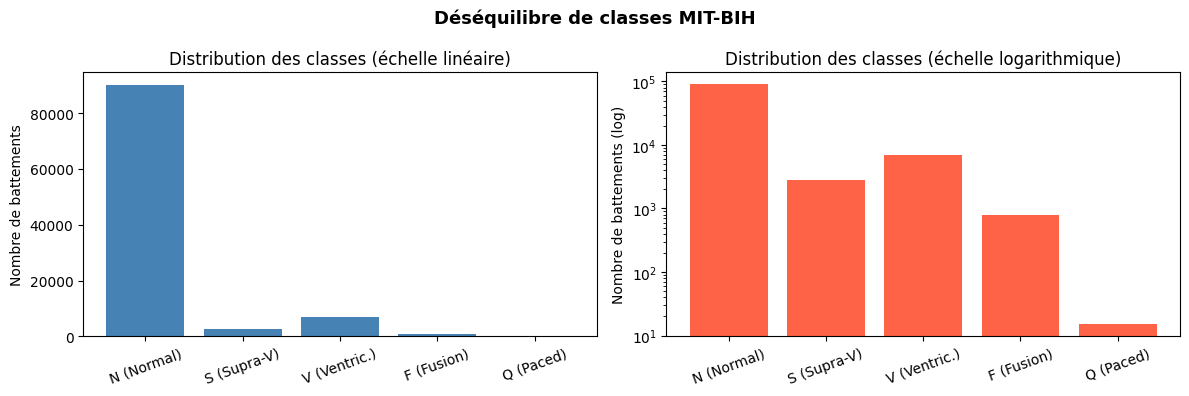


Observation : la classe N (Normal) représente ~80 % des battements.
→ L'accuracy seule est une métrique trompeuse.
→ On utilisera le Macro F1 et la Sensibilité par classe.


In [31]:
# Tableau descriptif du déséquilibre de classes
df_desc = dataset.describe()
display(df_desc)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(df_desc['Classe'], df_desc['Nombre de beats'], color='steelblue')
axes[0].set_title('Distribution des classes (échelle linéaire)')
axes[0].set_ylabel('Nombre de battements')
axes[0].tick_params(axis='x', rotation=20)

axes[1].bar(df_desc['Classe'], df_desc['Nombre de beats'], color='tomato', log=True)
axes[1].set_title('Distribution des classes (échelle logarithmique)')
axes[1].set_ylabel('Nombre de battements (log)')
axes[1].tick_params(axis='x', rotation=20)

plt.suptitle('Déséquilibre de classes MIT-BIH', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print('\nObservation : la classe N (Normal) représente ~80 % des battements.')
print('→ L\'accuracy seule est une métrique trompeuse.')
print('→ On utilisera le Macro F1 et la Sensibilité par classe.')

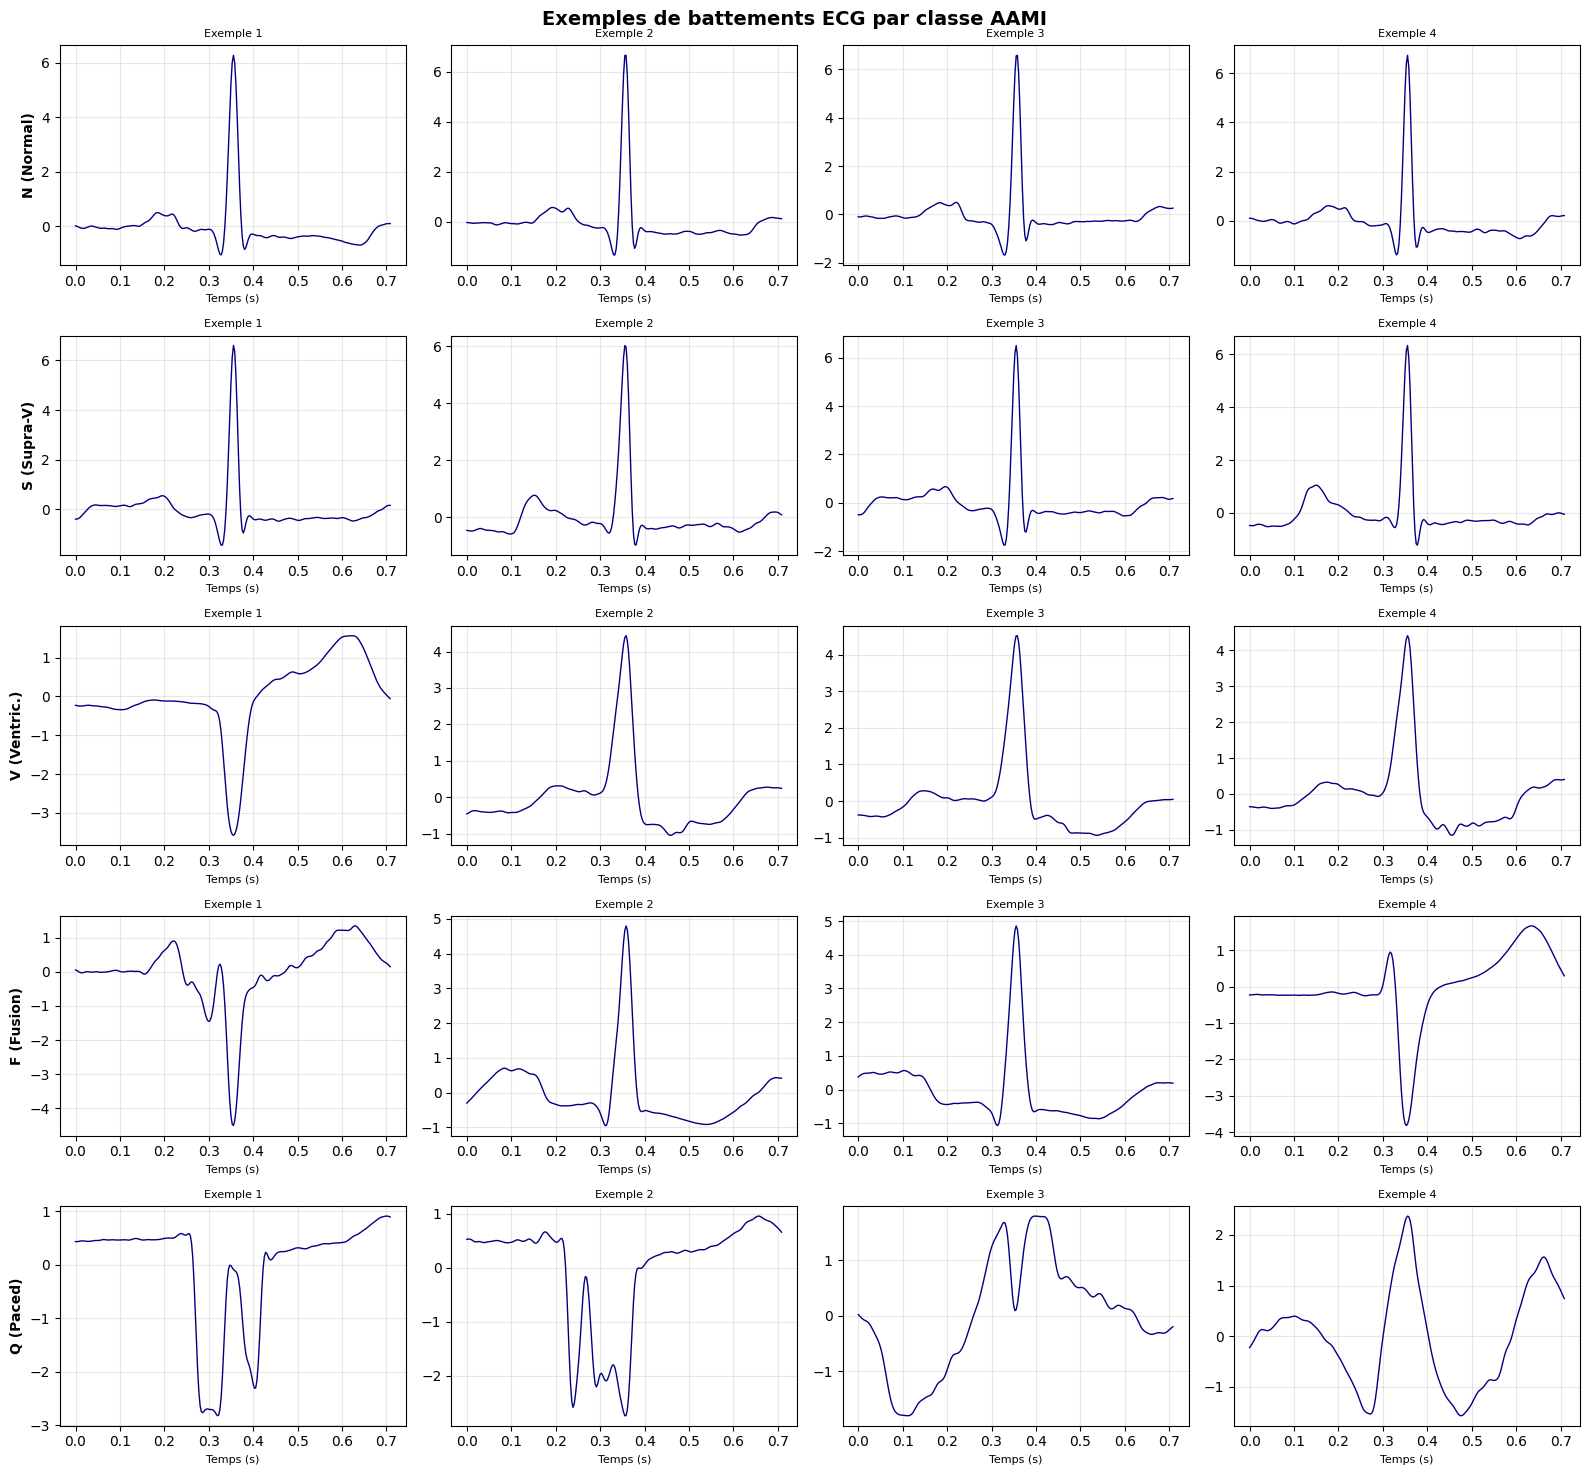

In [33]:
# Affichage d'exemples de signaux ECG par classe
# Utilisation de la taille réelle du signal (X_train.shape[1]) au lieu de WINDOW_SIZE
signal_length = X_train.shape[1]
t = np.arange(signal_length) / FS  # axe temporel ajusté en secondes

fig, axes = plt.subplots(len(CLASS_NAMES), 4, figsize=(16, 3 * len(CLASS_NAMES)))

for cls_idx, cls_name in enumerate(CLASS_NAMES):
    idx_cls = np.where(y_train == cls_idx)[0]
    if len(idx_cls) == 0:
        continue
    chosen  = idx_cls[:4]
    for col, idx in enumerate(chosen):
        axes[cls_idx, col].plot(t, X_train[idx], lw=1.0, color='navy')
        if col == 0:
            axes[cls_idx, col].set_ylabel(cls_name, fontsize=10, fontweight='bold')
        axes[cls_idx, col].set_xlabel('Temps (s)', fontsize=8)
        axes[cls_idx, col].grid(alpha=0.3)
        axes[cls_idx, col].set_title(f'Exemple {col + 1}', fontsize=8)

plt.suptitle('Exemples de battements ECG par classe AAMI', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### Note : augmentation de données

Les techniques d'augmentation (jittering, time warping, magnitude warping) sont **implémentées**
dans `src/augmentation.py` mais ne sont **pas utilisées** dans ce pipeline.

Le déséquilibre de classes est géré exclusivement par la **pondération de la loss**
(Étape 5), ce qui :
- Préserve la distribution réelle des données (pas de données synthétiques)
- Réduit le temps d'entraînement
- Évite le risque d'overfitting sur les classes minoritaires augmentées


---
## Étape 3b — Visualisations approfondies des données

Cette section explore les données ECG sous plusieurs angles complémentaires :
- **Prototypes de classes** : signal moyen ± écart-type par classe
- **Distribution statistique** : amplitude, énergie, zero-crossing par classe
- **Spectre fréquentiel** : FFT moyenne par classe
- **Intervalles RR** : variabilité inter-battements
- **t-SNE** : projection 2D pour visualiser la séparabilité
- **Matrice de corrélation** des features extraites


In [ ]:
# ── Viz 1 : Prototypes de classes (signal moyen ± écart-type) ──
t = np.arange(WINDOW_SIZE) / FS  # axe temporel en secondes

colors = ['#2196F3', '#4CAF50', '#F44336', '#FF9800', '#9C27B0']
fig, axes = plt.subplots(1, 5, figsize=(20, 3), sharey=True)

for cls_idx, (cls_name, color) in enumerate(zip(CLASS_NAMES, colors)):
    beats_cls = X_all[y_all == cls_idx]  # tous les beats de cette classe
    if len(beats_cls) == 0:
        continue
    mean = beats_cls.mean(axis=0)
    std  = beats_cls.std(axis=0)
    ax = axes[cls_idx]
    ax.fill_between(t, mean - std, mean + std, alpha=0.2, color=color)
    ax.plot(t, mean, color=color, lw=2)
    ax.set_title(f'{cls_name}\nn={len(beats_cls):,}', fontsize=9)
    ax.set_xlabel('Temps (s)', fontsize=8)
    ax.grid(alpha=0.3)
    if cls_idx == 0:
        ax.set_ylabel('Amplitude (u.a.)', fontsize=8)

plt.suptitle('Prototype de chaque classe AAMI (μ ± σ)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()
print('Observation : les classes V et S montrent des déformations morphologiques distinctes du QRS.')


In [ ]:
# ── Viz 2 : Distribution de statistiques temporelles par classe ──
# On extrait 3 features simples : amplitude crête-à-crête, énergie, zero-crossing rate
amplitudes = X_all.max(axis=1) - X_all.min(axis=1)
energies   = (X_all ** 2).mean(axis=1)
zcr        = (np.diff(np.sign(X_all), axis=1) != 0).sum(axis=1) / WINDOW_SIZE

import pandas as pd
df_stats = pd.DataFrame({
    'Classe'      : [CLASS_NAMES[y] for y in y_all],
    'Amplitude'   : amplitudes,
    'Énergie'     : energies,
    'ZCR'         : zcr,
})

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, feat in zip(axes, ['Amplitude', 'Énergie', 'ZCR']):
    order = CLASS_NAMES
    data_by_class = [df_stats[df_stats['Classe']==c][feat].values for c in order]
    bp = ax.boxplot(data_by_class, patch_artist=True, notch=True,
                    medianprops=dict(color='black', lw=2))
    colors_box = ['#2196F3','#4CAF50','#F44336','#FF9800','#9C27B0']
    for patch, color in zip(bp['boxes'], colors_box):
        patch.set_facecolor(color)
        patch.set_alpha(0.6)
    ax.set_xticklabels([c.split()[0] for c in order], rotation=20)
    ax.set_title(feat, fontweight='bold')
    ax.grid(alpha=0.3, axis='y')

plt.suptitle('Distribution des features temporelles par classe', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


In [ ]:
# ── Viz 3 : Spectre fréquentiel moyen par classe (FFT) ──
freqs = np.fft.rfftfreq(WINDOW_SIZE, d=1.0/FS)  # axe de fréquences en Hz

fig, axes = plt.subplots(1, 5, figsize=(20, 3), sharey=True)

for cls_idx, (cls_name, color) in enumerate(zip(CLASS_NAMES, colors)):
    beats_cls = X_all[y_all == cls_idx]
    if len(beats_cls) == 0:
        continue
    fft_mean = np.abs(np.fft.rfft(beats_cls, axis=1)).mean(axis=0)
    ax = axes[cls_idx]
    ax.plot(freqs, fft_mean, color=color, lw=1.5)
    ax.fill_between(freqs, fft_mean, alpha=0.2, color=color)
    ax.set_title(cls_name.split()[0], fontsize=9)
    ax.set_xlabel('Fréquence (Hz)', fontsize=8)
    ax.set_xlim(0, FS/2)
    ax.grid(alpha=0.3)
    if cls_idx == 0:
        ax.set_ylabel('|FFT| moyen', fontsize=8)

plt.suptitle('Spectre fréquentiel moyen par classe AAMI', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()
print('Les battements ventriculaires (V) présentent une énergie plus élevée à basse fréquence.')


In [ ]:
# ── Viz 4 : Matrice de corrélation des features manuelles ──
from scipy.stats import skew, kurtosis

# Extraire un sous-échantillon équilibré (max 1000 par classe)
rng_corr = np.random.default_rng(42)
idx_sub = []
for cls in range(5):
    idx_cls = np.where(y_all == cls)[0]
    chosen  = rng_corr.choice(idx_cls, size=min(1000, len(idx_cls)), replace=False)
    idx_sub.extend(chosen.tolist())
idx_sub = np.array(idx_sub)
X_sub   = X_all[idx_sub]
y_sub   = y_all[idx_sub]

features_dict = {
    'Moyenne'        : X_sub.mean(axis=1),
    'Écart-type'     : X_sub.std(axis=1),
    'Amplitude'      : X_sub.max(axis=1) - X_sub.min(axis=1),
    'Énergie'        : (X_sub**2).mean(axis=1),
    'Skewness'       : skew(X_sub, axis=1),
    'Kurtosis'       : kurtosis(X_sub, axis=1),
    'ZCR'            : (np.diff(np.sign(X_sub), axis=1) != 0).sum(axis=1) / WINDOW_SIZE,
    'Max positif'    : X_sub.max(axis=1),
    'Min (abs)'      : np.abs(X_sub.min(axis=1)),
}

df_feat = pd.DataFrame(features_dict)
corr    = df_feat.corr()

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr.values, cmap='coolwarm', vmin=-1, vmax=1, aspect='auto')
plt.colorbar(im, ax=ax)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=45, ha='right')
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.values[i,j]:.2f}', ha='center', va='center', fontsize=7,
                color='white' if abs(corr.values[i,j]) > 0.6 else 'black')
ax.set_title('Matrice de corrélation des features manuelles', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


In [ ]:
# ── Viz 5 : Variabilité des intervalles RR chargés dans le npz ──
# Le fichier contient une colonne 'rr' avec les intervalles pré/post battement
with np.load(Path('data/mitdb_beats.npz'), allow_pickle=False) as f:
    rr_data = f['rr'][idx_sub]  # shape (N_sub, 4)

# rr[:,0] est typiquement l'intervalle RR précédent le battement
rr_pre = rr_data[:, 0]  # intervalle RR précédent (en samples)

fig, axes = plt.subplots(1, 5, figsize=(20, 3), sharey=True)

for cls_idx, (cls_name, color) in enumerate(zip(CLASS_NAMES, colors)):
    mask = y_sub == cls_idx
    rr_cls = rr_pre[mask]
    if len(rr_cls) < 2:
        continue
    ax = axes[cls_idx]
    # Filtrer les valeurs aberrantes (>2s ou <0.2s à 360Hz)
    rr_filt = rr_cls[(rr_cls > 0.2*FS) & (rr_cls < 2.0*FS)] / FS * 1000  # en ms
    ax.hist(rr_filt, bins=40, color=color, alpha=0.75, edgecolor='white')
    ax.axvline(rr_filt.mean(), color='black', lw=1.5, linestyle='--',
               label=f'μ={rr_filt.mean():.0f}ms')
    ax.set_title(cls_name.split()[0], fontsize=9)
    ax.set_xlabel('RR (ms)', fontsize=8)
    ax.legend(fontsize=7)
    ax.grid(alpha=0.3)

plt.suptitle('Distribution des intervalles RR par classe', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()
print('Les battements ventriculaires (V) tendent à avoir des intervalles RR plus courts (prématurés).')


In [ ]:
# ── Viz 6 : Projection t-SNE 2D pour la séparabilité des classes ──
# Note : t-SNE est coûteux — on travaille sur un sous-échantillon équilibré (500/classe)
from sklearn.manifold    import TSNE
from sklearn.preprocessing import StandardScaler

# Sous-échantillon stratifié
rng_tsne = np.random.default_rng(42)
idx_tsne = []
for cls in range(5):
    idx_cls = np.where(y_all == cls)[0]
    chosen  = rng_tsne.choice(idx_cls, size=min(500, len(idx_cls)), replace=False)
    idx_tsne.extend(chosen.tolist())
idx_tsne = np.array(idx_tsne)

X_tsne = StandardScaler().fit_transform(X_all[idx_tsne])
y_tsne = y_all[idx_tsne]

print('Calcul du t-SNE (peut prendre 1–2 minutes)…')
emb = TSNE(n_components=2, random_state=42, perplexity=40, n_iter=1000).fit_transform(X_tsne)

fig, ax = plt.subplots(figsize=(9, 7))
for cls_idx, (cls_name, color) in enumerate(zip(CLASS_NAMES, colors)):
    mask = y_tsne == cls_idx
    ax.scatter(emb[mask, 0], emb[mask, 1], s=6, alpha=0.5,
               color=color, label=cls_name)

ax.legend(markerscale=3, fontsize=9)
ax.set_title('Projection t-SNE des battements ECG (500 par classe)', fontsize=13, fontweight='bold')
ax.set_xlabel('t-SNE 1'); ax.set_ylabel('t-SNE 2')
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()
print('Un bon regroupement des classes facilite la classification — les classes chevauchées seront plus difficiles.')


## Dans ce projet, les techniques d'augmentation de données servent principalement à :

* **Rééquilibrer les classes minoritaires** en les sur-échantillonnant artificiellement pour qu'elles atteignent au minimum 30 % de la classe majoritaire avant l'entraînement.


* **Enrichir la diversité des signaux** à l'aide de transformations (comme le *jittering*, le *time warping* ou le *magnitude warping*) afin d'aider les modèles à mieux généraliser face à la variabilité naturelle des battements cardiaques.

---
## Étape 4 — Baseline : features manuelles + Random Forest

Avant les modèles deep learning, on établit une **baseline solide** avec :
- Extraction de features statistiques et fréquentielles sur chaque battement
- Classifieur Random Forest

Cette baseline sert de **seuil minimal** à dépasser et permet de quantifier
l'apport réel du deep learning.


In [ ]:
from sklearn.ensemble        import RandomForestClassifier
from sklearn.preprocessing   import StandardScaler

print('Extraction des features manuelles…')
extractor = HandcraftedFeatureExtractor()
X_train_feat = extractor.transform(X_train)
X_val_feat   = extractor.transform(X_val)
X_test_feat  = extractor.transform(X_test)

print(f'Dimension des features : {X_train_feat.shape[1]} par battement')

# Normalisation (importante pour certains classifieurs, bonne pratique générale)
scaler = StandardScaler()
X_train_feat = scaler.fit_transform(X_train_feat)
X_val_feat   = scaler.transform(X_val_feat)
X_test_feat  = scaler.transform(X_test_feat)

print('Entraînement du Random Forest…')
rf = RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=SEED, class_weight='balanced')
rf.fit(X_train_feat, y_train)

y_pred_rf = rf.predict(X_test_feat)
metrics_rf = compute_metrics(y_test, y_pred_rf, class_names=CLASS_NAMES)

print('\n── Rapport de classification (Random Forest) ──')
print(metrics_rf['report_str'])
print(f'Macro F1  : {metrics_rf["macro_f1"]:.4f}')
print(f'Accuracy  : {metrics_rf["accuracy"]:.4f}')

plot_confusion_matrix(metrics_rf['conf_matrix'], CLASS_NAMES, title='Random Forest')

---
## Étape 5 — Modèles Deep Learning

Trois architectures sont comparées :

| Architecture | Philosophie | Points forts |
|---|---|---|
| **CNN1D** | Motifs locaux par convolution | Léger, rapide à entraîner |
| **ResNet1D** | Connexions résiduelles → réseau profond | Meilleure généralisation |
| **CNN-LSTM** | Local (CNN) + temporel long (LSTM) + attention | Interprétabilité par attention |

### Stratégie de gestion du déséquilibre de classes

Au lieu de sur-échantillonner les classes minoritaires par augmentation, on opte pour une
**pondération de la loss** (class-weighted CrossEntropyLoss).

Le poids de chaque classe est inversement proportionnel à sa fréquence dans l'ensemble d'entraînement :

$$w_c = \\frac{N}{K \\cdot N_c}$$

où $N$ est le nombre total de battements, $K$ le nombre de classes, et $N_c$ le nombre de battements
de la classe $c$. Cela force le modèle à accorder **autant d'importance aux classes rares**
(S, V, F, Q) qu'à la classe majoritaire N, sans modifier la distribution réelle des données.


In [ ]:
# Calcul des poids de classe (inversement proportionnels à la fréquence)
# Ces poids seront passés à la CrossEntropyLoss dans le Trainer
import torch

classes, counts = np.unique(y_train, return_counts=True)
N = len(y_train)
K = len(classes)

class_weights = N / (K * counts)  # w_c = N / (K * N_c)
class_weights = class_weights / class_weights.sum() * K  # normalisation

print('Poids de classe calculés :')
for cls_idx, (cls_name, w, cnt) in enumerate(zip(CLASS_NAMES, class_weights, counts)):
    print(f'  {cls_name:<20} : {cnt:>7,} beats → poids = {w:.4f}')

# Visualisation des poids
fig, ax = plt.subplots(figsize=(8, 3))
bars = ax.bar(CLASS_NAMES, class_weights,
              color=['#2196F3','#4CAF50','#F44336','#FF9800','#9C27B0'])
ax.set_ylabel('Poids de classe')
ax.set_title('Poids de classe (inversement proportionnels à la fréquence)', fontweight='bold')
for bar, w in zip(bars, class_weights):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.05,
            f'{w:.2f}', ha='center', fontsize=9)
ax.tick_params(axis='x', rotation=20)
ax.grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

# Tenseur PyTorch des poids
weights_tensor = torch.tensor(class_weights, dtype=torch.float32)


In [ ]:
# DataLoaders — données originales SANS sur-échantillonnage
# Le rééquilibrage est géré uniquement par les poids de la loss
BATCH_SIZE = 256
train_loader, val_loader = make_loaders(
    X_train, y_train,   # distribution réelle, non modifiée
    X_val,   y_val,
    BATCH_SIZE
)
print(f'Train loader : {len(train_loader)} batches × {BATCH_SIZE} = {len(train_loader)*BATCH_SIZE:,} échantillons/epoch')
print(f'Val loader   : {len(val_loader)} batches')


In [ ]:
# ── 5a. CNN1D ── avec pondération de la loss
set_seed(SEED)
model_cnn   = CNN1D(n_classes=5)
trainer_cnn = Trainer(model_cnn, epochs=30, lr=1e-3, save_dir='../results')
# On passe y_train pour que le Trainer calcule (ou reçoive) les poids de classe
history_cnn = trainer_cnn.fit(train_loader, val_loader, y_train=y_train, model_name='cnn1d')
plot_learning_curves(history_cnn, model_name='CNN1D')


In [ ]:
# ── 5b. ResNet1D ── avec pondération de la loss
set_seed(SEED)
model_resnet   = ResNet1D(n_classes=5)
trainer_resnet = Trainer(model_resnet, epochs=30, lr=1e-3, save_dir='../results')
history_resnet = trainer_resnet.fit(train_loader, val_loader, y_train=y_train, model_name='resnet1d')
plot_learning_curves(history_resnet, model_name='ResNet1D')


In [ ]:
# ── 5c. CNN-LSTM avec attention ── avec pondération de la loss
set_seed(SEED)
model_cnnlstm   = CNN_LSTM(n_classes=5)
trainer_cnnlstm = Trainer(model_cnnlstm, epochs=30, lr=5e-4, save_dir='../results')
history_cnnlstm = trainer_cnnlstm.fit(train_loader, val_loader, y_train=y_train, model_name='cnn_lstm')
plot_learning_curves(history_cnnlstm, model_name='CNN-LSTM')


---
## Étape 6 — Évaluation clinique sur le jeu de test

L'évaluation est réalisée sur des **patients jamais vus** pendant l'entraînement.
On calcule les métriques médicales recommandées par la norme **AAMI EC57** :
sensibilité, spécificité, VPP, F1 par classe, Macro F1.


In [ ]:
all_results = {}

for name, model in [('CNN1D', model_cnn), ('ResNet1D', model_resnet), ('CNN-LSTM', model_cnnlstm)]:
    y_pred, y_prob = predict(model, X_test, device=DEVICE)
    metrics = compute_metrics(y_test, y_pred, class_names=CLASS_NAMES)
    all_results[name] = metrics

    print(f'\n══ {name} ══')
    print(metrics['report_str'])
    plot_confusion_matrix(metrics['conf_matrix'], CLASS_NAMES, title=f'Confusion — {name}',
                          save_path=f'../results/{name.lower()}_confusion.png')
    plot_metrics_by_class(metrics, CLASS_NAMES,
                          save_path=f'../results/{name.lower()}_metrics.png')

In [ ]:
# Tableau récapitulatif
compare_models(all_results)

# Graphique de comparaison du Macro F1
names    = list(all_results.keys())
macro_f1 = [all_results[n]['macro_f1'] for n in names]
accuracy = [all_results[n]['accuracy']  for n in names]

x = np.arange(len(names))
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(x - 0.2, macro_f1, 0.4, label='Macro F1', color='steelblue')
ax.bar(x + 0.2, accuracy,  0.4, label='Accuracy',  color='tomato')
ax.set_xticks(x)
ax.set_xticklabels(names)
ax.set_ylim(0, 1.05)
ax.set_ylabel('Score')
ax.set_title('Comparaison des architectures sur le jeu de test')
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('../results/comparison.png', dpi=150)
plt.show()

---
## Étape 7 — Interprétabilité

L'interprétabilité est fondamentale en médecine : le modèle doit pouvoir
**justifier ses décisions** pour être validé par des cardiologues.

- **GradCAM** : montre *où* le CNN regarde dans le signal
- **Attention** : montre *quels instants* le LSTM considère critiques
- **Filtres** : révèle les *motifs primitifs* appris par le CNN


In [ ]:
# GradCAM sur le ResNet1D
# On cible la dernière couche convolutive du dernier bloc résiduel
target_layer = list(model_resnet.layer3.modules())[-1]  # dernière BN du bloc 3
# Retrouver la dernière Conv1d
for m in model_resnet.layer3.modules():
    if isinstance(m, torch.nn.Conv1d):
        target_layer = m

gradcam = GradCAM1D(model_resnet, target_layer, device=torch.device(DEVICE))

# Exemple : un battement ventriculaire (V)
idx_v   = np.where(y_test == 2)[0][0]
x_v     = torch.from_numpy(X_test[idx_v:idx_v+1]).unsqueeze(1).float()
heatmap = gradcam.compute(x_v, class_idx=2)

plot_gradcam(
    signal   = X_test[idx_v],
    heatmap  = heatmap,
    fs       = FS,
    title    = 'GradCAM — Battement ventriculaire (V) — ResNet1D',
    save_path= '../results/gradcam_ventricular.png',
)
gradcam.remove_hooks()

In [ ]:
# Poids d'attention CNN-LSTM sur un battement supraventriculaire (S)
model_cnnlstm.eval()
idx_s = np.where(y_test == 1)[0][0]
x_s   = torch.from_numpy(X_test[idx_s:idx_s+1]).unsqueeze(1).float().to(DEVICE)

with torch.no_grad():
    _, attn_weights = model_cnnlstm(x_s)

attn_np = attn_weights[0].cpu().numpy()

plot_attention_weights(
    signal       = X_test[idx_s],
    attn_weights = attn_np,
    fs           = FS,
    title        = 'Attention — Battement supraventriculaire (S) — CNN-LSTM',
    save_path    = '../results/attention_supraventricular.png',
)

In [ ]:
# Filtres convolutifs de la première couche CNN1D
plot_conv_filters(model_cnn, n_filters=16, save_path='../results/conv_filters.png')

In [ ]:
# Analyse des exemples mal classés par le meilleur modèle
y_pred_best, _ = predict(model_resnet, X_test, device=DEVICE)
plot_misclassified(
    X_test, y_test, y_pred_best, CLASS_NAMES, fs=FS,
    save_path='../results/misclassified.png'
)

---
## Conclusion

Ce projet a démontré une approche complète de classification de séries temporelles médicales :

### Apports méthodologiques
- **Stratification par patient** : évite le data leakage, donne une estimation réaliste des performances
- **Augmentation ciblée** : rééquilibre les classes sans distordre la physiologie
- **Loss pondérée** : accorde plus d'importance aux arythmies critiques rares
- **Métriques médicales** : sensibilité, spécificité et VPP plutôt que la seule accuracy

### Comparaison des architectures
| Architecture | Avantage | Limite |
|---|---|---|
| Random Forest | Interprétable, rapide | Performances limitées sur les classes rares |
| CNN1D | Léger, bon compromis | Ignore les dépendances longues |
| ResNet1D | Profond, généralise bien | Boîte noire |
| CNN-LSTM | Capture long terme + attention | Plus lent, plus complexe |

### Pistes d'amélioration
- Transfer learning depuis des ECG pré-entraînés sur de plus grandes bases
- Transformer / Self-Attention pour remplacer le LSTM
- Utilisation multi-leads (12 dérivations) pour les bases PTB/PTBXL
